#### Importing necessary libraries

In [0]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### list of files in dbfs

In [0]:
%fs ls dbfs:///FileStore/tables/

path,name,size,modificationTime
dbfs:/FileStore/tables/Customers__1_-1.csv,Customers__1_-1.csv,1043,1710705699000
dbfs:/FileStore/tables/Customers__1_.csv,Customers__1_.csv,1043,1710705669000
dbfs:/FileStore/tables/Drugs_package.csv,Drugs_package.csv,27234691,1707889380000
dbfs:/FileStore/tables/Drugs_product.csv,Drugs_product.csv,38743242,1707889380000
dbfs:/FileStore/tables/EmployeeSale__1_.csv,EmployeeSale__1_.csv,2736,1710705733000
dbfs:/FileStore/tables/Employee__1_.csv,Employee__1_.csv,385,1710705688000
dbfs:/FileStore/tables/Gender_crosswalk.txt,Gender_crosswalk.txt,72,1709286187000
dbfs:/FileStore/tables/Products__1_.csv,Products__1_.csv,367,1710705650000
dbfs:/FileStore/tables/Relationship_crosswalk.txt,Relationship_crosswalk.txt,264,1709286188000
dbfs:/FileStore/tables/Sales__1_.csv,Sales__1_.csv,2714,1710705719000


####Load data from CSV files into Spark DataFrames and display them.

In [0]:
%python
sales = spark.read.format("csv") \
    .option('header', True) \
    .option('inferSchema', True) \
    .option('delimiter', '\t') \
    .load("dbfs:/FileStore/tables/sales")
display(sales)
customers = spark.read.format("csv") \
    .option('header', True) \
    .option('inferSchema', True) \
    .option('delimiter', '\t') \
    .load("dbfs:/FileStore/tables/customers")
display(customers)
products = spark.read.format("csv") \
    .option('header', True) \
    .option('inferSchema', True) \
    .option('delimiter', '\t') \
    .load("dbfs:/FileStore/tables/products")
display(products)
employee = spark.read.format("csv") \
    .option('header', True) \
    .option('inferSchema', True) \
    .option('delimiter', '\t') \
    .load("dbfs:/FileStore/tables/employee")
display(employee)
employee_sales = spark.read.format("csv") \
    .option('header', True) \
    .option('inferSchema', True) \
    .option('delimiter', '\t') \
    .load("dbfs:/FileStore/tables/employee_sales")
display(employee_sales)






transaction_id,customer_id,product_id,transaction_date,amount_paid
1,3,3,01/05/23 00:00,613
2,19,9,03/07/23 00:00,227
3,9,10,25/10/23 00:00,891
4,4,3,28/05/23 00:00,342
5,15,6,18/04/23 00:00,91
6,14,9,27/09/23 00:00,391
7,6,1,16/12/23 00:00,654
8,13,2,09/12/23 00:00,920
9,17,6,07/07/23 00:00,151
10,19,5,12/09/23 00:00,667


customer_id,name,email,phone
1,Customer 1,customer1@example.com,123-456-0001
2,Customer 2,customer2@example.com,123-456-0002
3,Customer 3,customer3@example.com,123-456-0003
4,Customer 4,customer4@example.com,123-456-0004
5,Customer 5,customer5@example.com,123-456-0005
6,Customer 6,customer6@example.com,123-456-0006
7,Customer 7,customer7@example.com,123-456-0007
8,Customer 8,customer8@example.com,123-456-0008
9,Customer 9,customer9@example.com,123-456-0009
10,Customer 10,customer10@example.com,123-456-0010


product_id,product_name,category,price,stock_quantity
1,Product 1,Category 1,232,37
2,Product 2,Category 1,185,74
3,Product 3,Category 3,171,72
4,Product 4,Category 3,154,43
5,Product 5,Category 2,207,96
6,Product 6,Category 3,496,37
7,Product 7,Category 1,166,23
8,Product 8,Category 1,205,81
9,Product 9,Category 3,303,13
10,Product 10,Category 1,447,95


employee_id,employee_name,role,department
1,Employee 1,Role 2,Department 3
2,Employee 2,Role 2,Department 1
3,Employee 3,Role 1,Department 2
4,Employee 4,Role 1,Department 2
5,Employee 5,Role 1,Department 3
6,Employee 6,Role 3,Department 1
7,Employee 7,Role 3,Department 1
8,Employee 8,Role 3,Department 2
9,Employee 9,Role 2,Department 2
10,Employee 10,Role 3,Department 2


sale_id,employee_id,transaction_id,sale_date,amount
1,10,33,23/03/23 00:00,480
2,9,21,28/11/23 00:00,705
3,7,4,19/04/23 00:00,716
4,9,10,05/11/23 00:00,242
5,9,69,08/11/23 00:00,17
6,7,9,19/06/23 00:00,362
7,7,93,09/09/23 00:00,513
8,7,34,25/08/23 00:00,107
9,1,86,18/05/23 00:00,456
10,6,14,26/12/23 00:00,367


In [0]:
sales.display()

transaction_id,customer_id,product_id,transaction_date,amount_paid
1,3,3,01/05/23 00:00,613
2,19,9,03/07/23 00:00,227
3,9,10,25/10/23 00:00,891
4,4,3,28/05/23 00:00,342
5,15,6,18/04/23 00:00,91
6,14,9,27/09/23 00:00,391
7,6,1,16/12/23 00:00,654
8,13,2,09/12/23 00:00,920
9,17,6,07/07/23 00:00,151
10,19,5,12/09/23 00:00,667


####Convert Spark DataFrames to pandas DataFrames for further processing.

In [0]:
import pandas as pd

# Convert Spark DataFrames to pandas DataFrames
sales_df = sales.toPandas()
customers_df = customers.toPandas()
products_df = products.toPandas()
employee_df = employee.toPandas()
employee_sales_df = employee_sales.toPandas()


### Analyzing and Understanding  all five dataframes

In [0]:
sales_df

,transaction_id,customer_id,product_id,transaction_date,amount_paid
0,1,3,3,01/05/23 00:00,613
1,2,19,9,03/07/23 00:00,227
2,3,9,10,25/10/23 00:00,891
3,4,4,3,28/05/23 00:00,342
4,5,15,6,18/04/23 00:00,91
...,...,...,...,...,...
95,96,15,2,05/03/23 00:00,124
96,97,6,3,20/06/23 00:00,974
97,98,6,1,26/03/23 00:00,578
98,99,4,4,09/12/23 00:00,265


In [0]:
products_df

,product_id,product_name,category,price,stock_quantity
0,1,Product 1,Category 1,232,37
1,2,Product 2,Category 1,185,74
2,3,Product 3,Category 3,171,72
3,4,Product 4,Category 3,154,43
4,5,Product 5,Category 2,207,96
5,6,Product 6,Category 3,496,37
6,7,Product 7,Category 1,166,23
7,8,Product 8,Category 1,205,81
8,9,Product 9,Category 3,303,13
9,10,Product 10,Category 1,447,95


In [0]:
employee_df

,employee_id,employee_name,role,department
0,1,Employee 1,Role 2,Department 3
1,2,Employee 2,Role 2,Department 1
2,3,Employee 3,Role 1,Department 2
3,4,Employee 4,Role 1,Department 2
4,5,Employee 5,Role 1,Department 3
5,6,Employee 6,Role 3,Department 1
6,7,Employee 7,Role 3,Department 1
7,8,Employee 8,Role 3,Department 2
8,9,Employee 9,Role 2,Department 2
9,10,Employee 10,Role 3,Department 2


In [0]:
employee_sales_df

,sale_id,employee_id,transaction_id,sale_date,amount
0,1,10,33,23/03/23 00:00,480
1,2,9,21,28/11/23 00:00,705
2,3,7,4,19/04/23 00:00,716
3,4,9,10,05/11/23 00:00,242
4,5,9,69,08/11/23 00:00,17
...,...,...,...,...,...
95,96,8,46,09/03/23 00:00,664
96,97,4,36,28/06/23 00:00,10
97,98,5,30,20/07/23 00:00,949
98,99,10,20,19/04/23 00:00,355


#### 1.Create the countplot to get number of transaction made by each customer

####conclusion : from this countplot we can easily understand how many transaction made by each customer and from this information we can improve our bussiness model by working on less frequent customers

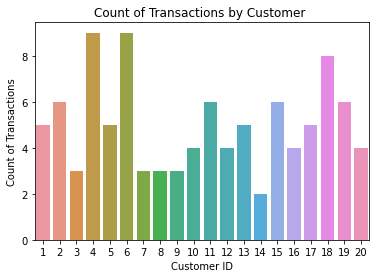

In [0]:
# Create the countplot to get number of transaction made by each customer
sns.countplot(data=sales_df, x='customer_id')
plt.title('Count of Transactions by Customer ')
plt.xlabel('Customer ID')
plt.ylabel('Count of Transactions')
plt.show()

### 2. create a countplot to  get number of transaction made on each product: 
####conclusion: The countplot provides an overview of transaction distribution across different products and it helps  in identifying popular products based on transaction frequency

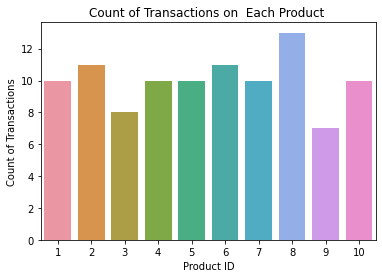

In [0]:
# create a countplot to  get number of transaction made on each product
sns.countplot(data=sales_df, x='product_id')
plt.title('Count of Transactions on  Each Product ')
plt.xlabel('Product ID')
plt.ylabel('Count of Transactions')
plt.show()


In [0]:
# to just cross check
s = sales_df[sales_df['product_id'] == 1]
s

,transaction_id,customer_id,product_id,transaction_date,amount_paid
6,7,6,1,16/12/23 00:00,654
14,15,15,1,07/02/23 00:00,612
38,39,14,1,07/08/23 00:00,250
46,47,3,1,06/12/23 00:00,676
59,60,10,1,21/11/23 00:00,292
74,75,2,1,10/03/23 00:00,25
83,84,18,1,17/07/23 00:00,484
86,87,1,1,07/04/23 00:00,25
93,94,18,1,08/02/23 00:00,305
97,98,6,1,26/03/23 00:00,578


In [0]:
total_amount_paid = sales_df.groupby('customer_id')['amount_paid'].sum()
total_amount_paid

Out[466]: customer_id
1     1328
2     1978
3     1985
4     4844
5     3190
6     4595
7     1087
8     1465
9     1325
10    2487
11    3214
12    1072
13    2950
14     641
15    2353
16    1179
17    2821
18    3677
19    3622
20    1138
Name: amount_paid, dtype: int32

####This code calculates the total sales by each product and  visualizes it using a bar plot to 
#### understand this easily
####conclusion : This chart displays the total sales amount for each product, helping to identify the best-selling  and lowest selling products at a glance.
#### so we can work on less selling  products to improve our sells

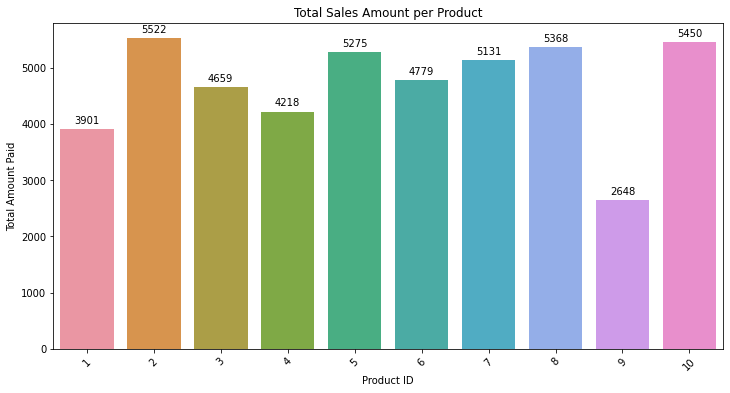

In [0]:


# Calculate total sales amount for each product
total_amount_paid = sales_df.groupby('product_id')['amount_paid'].sum().reset_index()

# Set the figure size
plt.figure(figsize=(12, 6))  # Adjust the width and height as needed

# Create bar plot
ax = sns.barplot(data=total_amount_paid, x='product_id', y='amount_paid')
plt.title('Total Sales Amount per Product')
plt.xlabel('Product ID')
plt.ylabel('Total Amount Paid')
plt.xticks(rotation=45)

# Adding values on respective bars
for index, row in total_amount_paid.iterrows():
    ax.text(row.name, row['amount_paid'] + 100, str(row['amount_paid']), ha='center', color='black')

plt.show()



In [0]:
total_amount_paid = sales_df.groupby('product_id')['amount_paid'].sum()
total_amount_paid

Out[468]: product_id
1     3901
2     5522
3     4659
4     4218
5     5275
6     4779
7     5131
8     5368
9     2648
10    5450
Name: amount_paid, dtype: int32

In [0]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   transaction_id    100 non-null    int32 
 1   customer_id       100 non-null    int32 
 2   product_id        100 non-null    int32 
 3   transaction_date  100 non-null    object
 4   amount_paid       100 non-null    int32 
dtypes: int32(4), object(1)
memory usage: 2.5+ KB


In [0]:


data = {
    'year': [2023]*12,
    'month': list(range(1, 13)),
    'total_sales_amount': [2038, 2319, 3203, 2953, 4876, 6602, 4238, 2009, 3283, 4622, 4440, 6368]
}

df = pd.DataFrame(data)
print(df)


    year  month  total_sales_amount
0   2023      1                2038
1   2023      2                2319
2   2023      3                3203
3   2023      4                2953
4   2023      5                4876
5   2023      6                6602
6   2023      7                4238
7   2023      8                2009
8   2023      9                3283
9   2023     10                4622
10  2023     11                4440
11  2023     12                6368


#### 5.visualize the monthly sales data from the DataFrame as a bar plot, where each bar represents the total sales amount for a specific month
#### conclusion : this graph is useful to understand monthly sales trends quickly 

####1.Bar Plot: Shows how much was sold each month, making it easy to compare sales between different months.

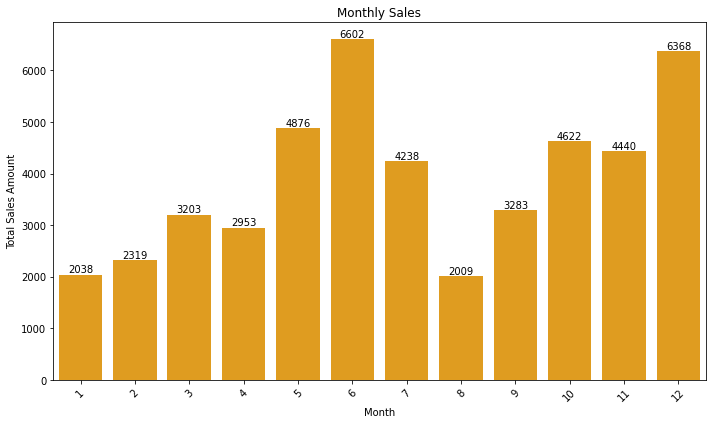

In [0]:
#visualize the monthly sales data from the DataFrame as a bar plot, where each bar represents the total sales 
#amount for a specific month
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='month', y='total_sales_amount', color='orange')

# Add total sales values on respective bars
for index, row in df.iterrows():
    plt.text(row.name, row['total_sales_amount'], str(row['total_sales_amount']), ha='center', va='bottom')

plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### 2.Line Chart: Displays how sales change month by month, helping to spot trends like sales increasing or decreasing over time.

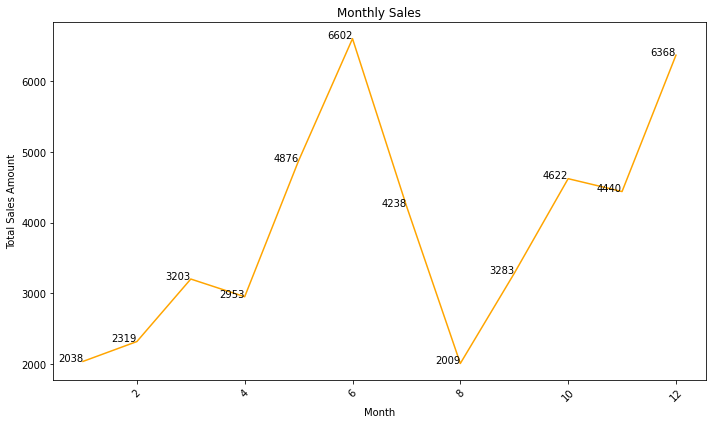

In [0]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='month', y='total_sales_amount', color='orange')
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)

# Adding annotations
for index, row in df.iterrows():
    plt.text(row['month'], row['total_sales_amount'], str(row['total_sales_amount']), ha='right')

plt.tight_layout()
plt.show()

#### 3.Pie Chart: Each slice represents a month's sales proportionately to the total sales, giving a clear visual of how much each month contributes in percentage terms

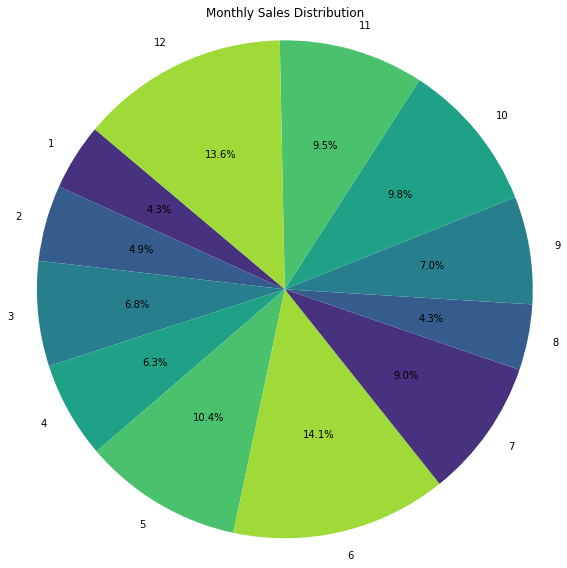

In [0]:


# Calculate total sales amount for each month
monthly_total_sales = df.groupby('month')['total_sales_amount'].sum()

# Plotting pie chart
plt.figure(figsize=(8, 8))
plt.pie(monthly_total_sales, labels=monthly_total_sales.index, autopct='%1.1f%%', startangle=140)
plt.title('Monthly Sales Distribution')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
plt.show()


In [0]:
employee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   employee_id    10 non-null     int32 
 1   employee_name  10 non-null     object
 2   role           10 non-null     object
 3   department     10 non-null     object
dtypes: int32(1), object(3)
memory usage: 408.0+ bytes


In [0]:
department_counts = employee_df['department'].value_counts()
department_counts

Out[475]: Department 2    5
Department 1    3
Department 3    2
Name: department, dtype: int64

####here we creates a pie chart  to visualize the distribution of employees across different departments,
####displaying the percentage of employees in each department.

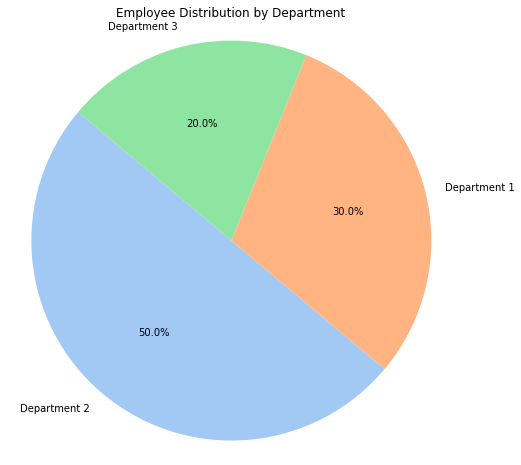

In [0]:



department_counts = employee_df['department'].value_counts()
plt.figure(figsize=(8, 8))
sns.set_palette("pastel")
plt.pie(department_counts, labels=department_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Employee Distribution by Department')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()


In [0]:
role_counts = employee_df['role'].value_counts()
role_counts

Out[477]: Role 3    4
Role 2    3
Role 1    3
Name: role, dtype: int64

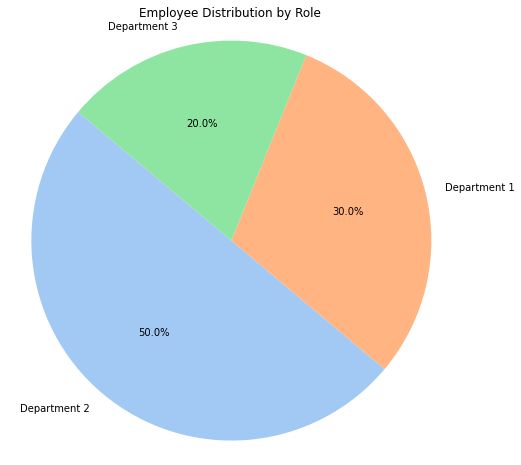

In [0]:
#here we creates a pie chart  to visualize the distribution of employees across different roles,
#displaying the percentage of employees in each role.

role_counts = employee_df['role'].value_counts()
plt.figure(figsize=(8, 8))
sns.set_palette("pastel")
plt.pie(department_counts, labels=department_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Employee Distribution by Role')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()


In [0]:
employee_sales_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   sale_id         100 non-null    int32 
 1   employee_id     100 non-null    int32 
 2   transaction_id  100 non-null    int32 
 3   sale_date       100 non-null    object
 4   amount          100 non-null    int32 
dtypes: int32(4), object(1)
memory usage: 2.5+ KB


In [0]:
total_sales_per_employee = employee_sales_df.groupby('employee_id')['amount'].sum().reset_index()
total_sales_per_employee

,employee_id,amount
0,1,5729
1,2,2992
2,3,2395
3,4,3024
4,5,5172
5,6,5853
6,7,4181
7,8,4064
8,9,10859
9,10,5327


#### 6.Visualizes total sales of each employee
#### conclusion:This bar plot provides a clear representation of the total sales made by each employee,so we can easily find highest and lowest performing employees

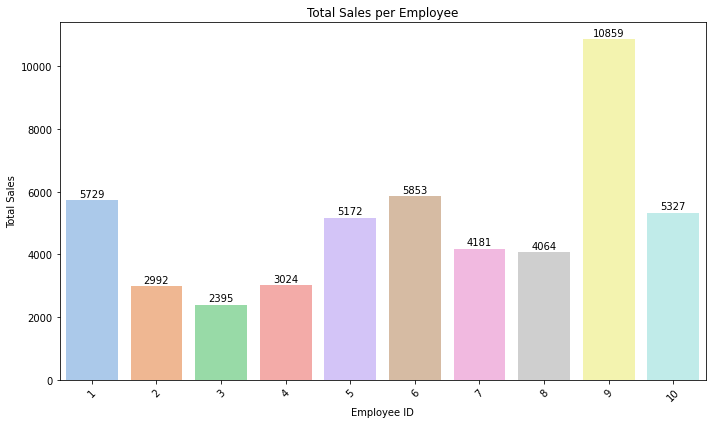

In [0]:
#here we create bar plot to get total sales of each employee

plt.figure(figsize=(10, 6))
sns.barplot(data=total_sales_per_employee, x='employee_id', y='amount')
plt.title('Total Sales per Employee')
plt.xlabel('Employee ID')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

# Adding total sales values on respective bars
for index, row in total_sales_per_employee.iterrows():
    plt.text(row.name, row['amount'] + 100, str(row['amount']), ha='center', color='black')

plt.tight_layout()
plt.show()


#### 7. visualizes the top 5 performing employees by total sales amount using a bar plot.
#### conclusion:It highlights the top 5 employees with the highest total sales amount, providing insights into employee performance and contribution to overall sales.

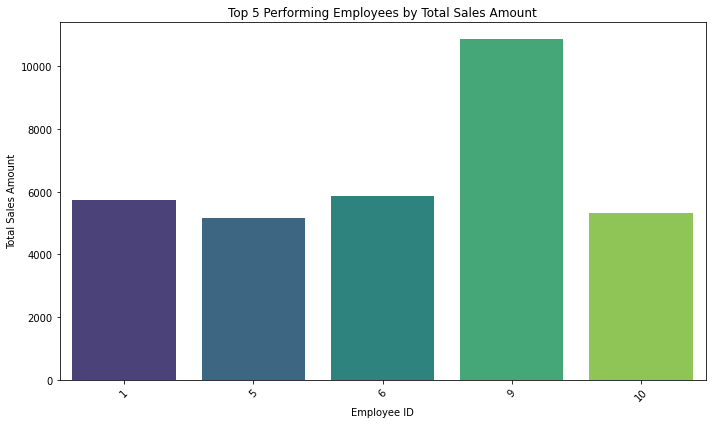

In [0]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group by employee_id and calculate total sales amount
total_sales_per_employee = employee_sales_df.groupby('employee_id')['amount'].sum().reset_index()

# Sort by total sales amount in descending order
top_5_employees = total_sales_per_employee.sort_values(by='amount', ascending=False).head(5)

# Create bar plot for top 5 performing employees
plt.figure(figsize=(10, 6))
sns.barplot(data=top_5_employees, x='employee_id', y='amount', palette='viridis')
plt.title('Top 5 Performing Employees by Total Sales Amount')
plt.xlabel('Employee ID')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


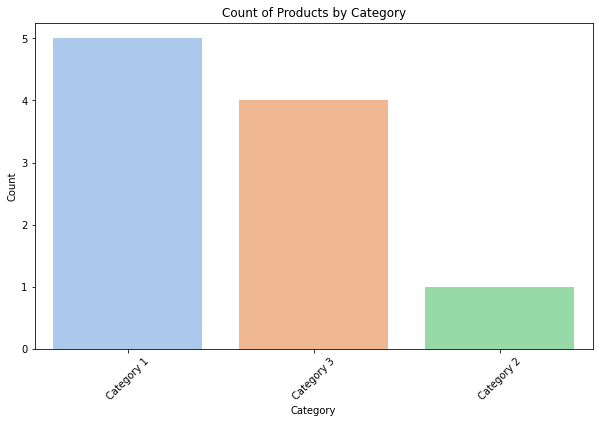

In [0]:
# count number of products in each category using countplot

plt.figure(figsize=(10, 6))
sns.countplot(data=products_df, x='category')
plt.title('Count of Products by Category')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()




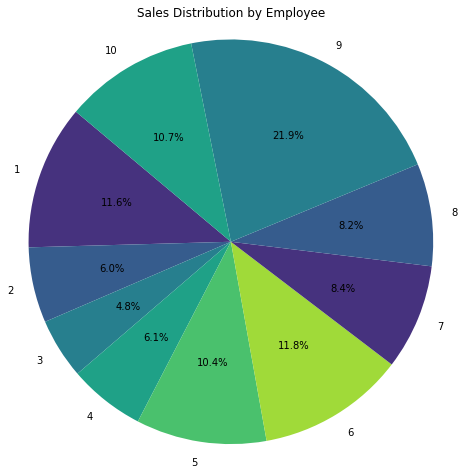

In [0]:
# Calculate total sales amount for each employee
total_sales_per_employee = employee_sales_df.groupby('employee_id')['amount'].sum()

# Create a pie chart using seaborn
plt.figure(figsize=(8, 8))
sns.set_palette("viridis")
plt.pie(total_sales_per_employee, labels=total_sales_per_employee.index, autopct='%1.1f%%', startangle=140)
plt.title('Sales Distribution by Employee')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()


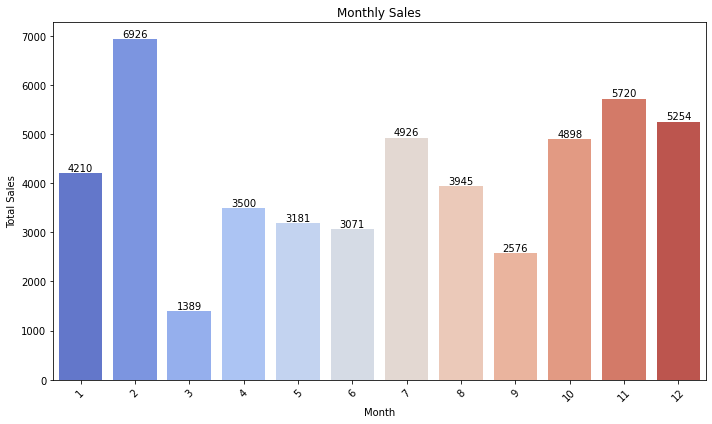

In [0]:

# Convert 'sale_date' column to datetime format
employee_sales_df['sale_date'] = pd.to_datetime(employee_sales_df['sale_date'])

# Extract month from 'sale_date' and create a new column 'sale_month'
employee_sales_df['sale_month'] = employee_sales_df['sale_date'].dt.month

# Group by sale_month and sum the amount column to get monthly sales
monthly_sales = employee_sales_df.groupby('sale_month')['amount'].sum().reset_index()


plt.figure(figsize=(10, 6))
sns.barplot(data=monthly_sales, x='sale_month', y='amount', palette='coolwarm')
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

# Adding sales values on respective bars
for index, row in monthly_sales.iterrows():
    plt.text(row.name, row['amount'], str(row['amount']), ha='center', va='bottom')

plt.tight_layout()
plt.show()


##dashboard
#### conclusion : This dashboard effectively presents key insights into sales performance, highlighting monthly sales trends, product popularity, employee sales contributions, and product category distribution, aiding in informed decision-making and strategic planning for sales optimization

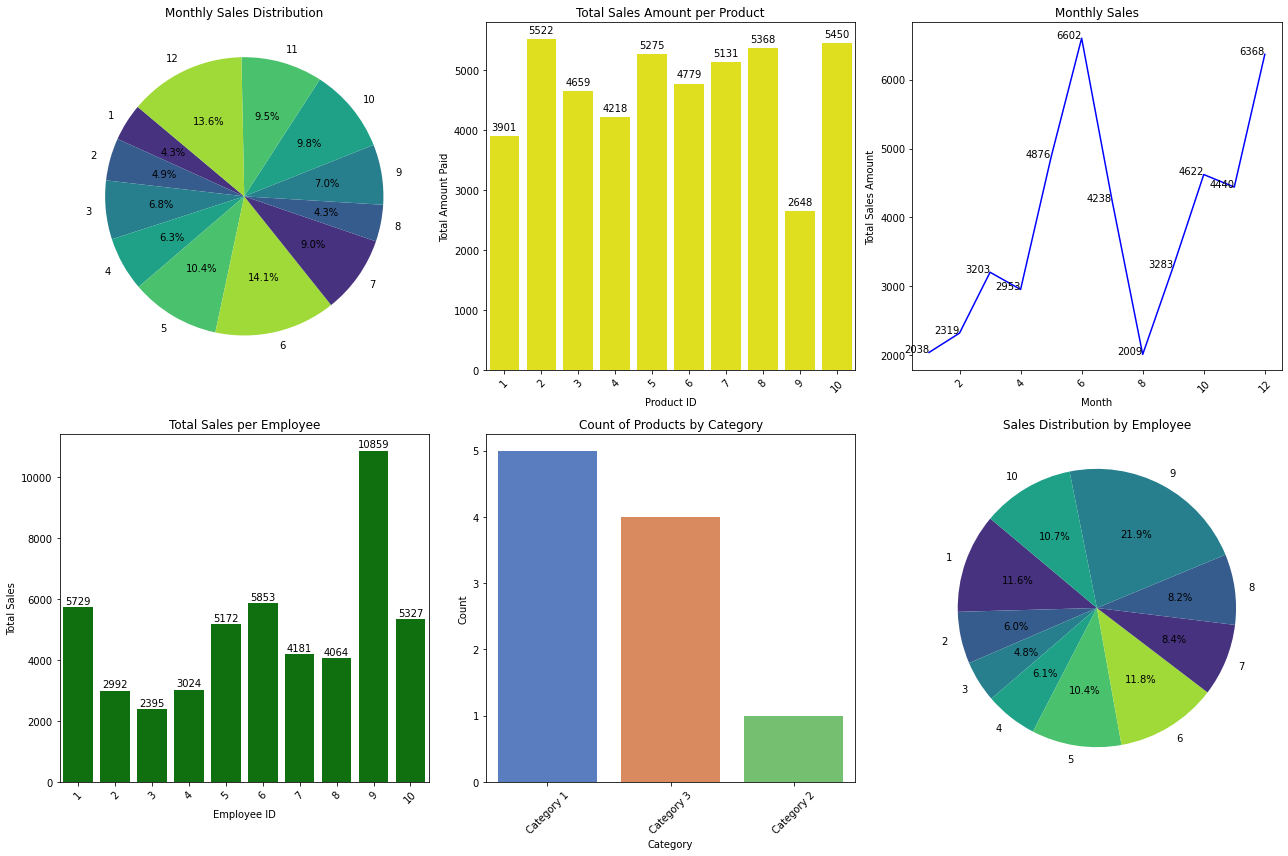

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create subplots with adjusted figure size
fig, axs = plt.subplots(2, 3, figsize=(18, 12))  

# Calculate total sales amount for each month
monthly_total_sales = df.groupby('month')['total_sales_amount'].sum().reset_index()

# Plot pie chart for monthly sales distribution
axs[0, 0].pie(monthly_total_sales['total_sales_amount'], labels=monthly_total_sales['month'], autopct='%1.1f%%', startangle=140)
axs[0, 0].set_title('Monthly Sales Distribution')

# Calculate total sales amount for each product
total_amount_paid = sales_df.groupby('product_id')['amount_paid'].sum().reset_index()

# Plot bar chart for total sales amount per product
sns.barplot(data=total_amount_paid, x='product_id', y='amount_paid', ax=axs[0, 1], color='yellow')
axs[0, 1].set_title('Total Sales Amount per Product')
axs[0, 1].set_xlabel('Product ID')
axs[0, 1].set_ylabel('Total Amount Paid')
axs[0, 1].tick_params(axis='x', rotation=45)

# Adding total sales values on respective bars
for index, row in total_amount_paid.iterrows():
    axs[0, 1].text(row.name, row['amount_paid'] + 100, str(row['amount_paid']), ha='center', color='black')

# Plot line chart for monthly sales
sns.lineplot(data=monthly_total_sales, x='month', y='total_sales_amount', ax=axs[0, 2], color='blue')
axs[0, 2].set_title('Monthly Sales')
axs[0, 2].set_xlabel('Month')
axs[0, 2].set_ylabel('Total Sales Amount')
axs[0, 2].tick_params(axis='x', rotation=45)
for index, row in monthly_total_sales.iterrows():
    axs[0, 2].text(row['month'], row['total_sales_amount'], str(row['total_sales_amount']), ha='right')

# Plot bar chart for total sales per employee
total_sales_per_employee = employee_sales_df.groupby('employee_id')['amount'].sum().reset_index()
sns.barplot(data=total_sales_per_employee, x='employee_id', y='amount', ax=axs[1, 0], color='green')
axs[1, 0].set_title('Total Sales per Employee')
axs[1, 0].set_xlabel('Employee ID')
axs[1, 0].set_ylabel('Total Sales')
axs[1, 0].tick_params(axis='x', rotation=45)
for index, row in total_sales_per_employee.iterrows():
    axs[1, 0].text(row.name, row['amount'] + 100, str(row['amount']), ha='center', color='black')

# Count number of products in each category using countplot
sns.countplot(data=products_df, x='category', ax=axs[1, 1], palette='muted')  # Add this countplot to the second row, second column
axs[1, 1].set_title('Count of Products by Category')
axs[1, 1].set_xlabel('Category')
axs[1, 1].set_ylabel('Count')
axs[1, 1].tick_params(axis='x', rotation=45)

# Plot pie chart for sales distribution by employee
axs[1, 2].pie(total_sales_per_employee['amount'], labels=total_sales_per_employee['employee_id'], autopct='%1.1f%%', startangle=140)
axs[1, 2].set_title('Sales Distribution by Employee in %')

# Adjust layout
plt.tight_layout()
plt.show()
